# Second Practice
### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336
##### We have been able to cooperate during the whole practice, very little individual work

In [48]:
# Necessary libraries
import numpy as np
import matplotlib.pyplot as plt

## 1. Gradient descent methods

### 1.1 A simple quadratic function

We will define $f$ as:
$$
    f(x)=x_{1}^{2} + x_{2}^{2}
$$

By derivating, we obtain the gradient:
$$
    \nabla f(x) = (2x_{1}, 2x_{2})
$$

Now we perform the next experiments

#### 1.1.1 Implement gradient descent with a constant $\alpha^{k} = 0.1$.

In [49]:
def grad_desc(f, grad_f, x0, alpha, max_iter):
    x=x0
    for i in range(max_iter):
        x = x -alpha * grad_f(x)
    return x, f(x)

def f(x): return x[0]**2 + x[1]**2
def grad_f(x): return np.array([2*x[0], 2*x[1]])

In [50]:
x0 = np.random.uniform(-200, 200, 2)

x_final, f_final = grad_desc(f, grad_f, x0, alpha=0.1, max_iter=100)

print(f"Initial point: x0   = [{x0[0]:.4f}, {x0[1]:.4f}]")
print(f"Final point:   x    = [{x_final[0]:.2e}, {x_final[1]:.2e}]")
print(f"Final value:   f(x) = {f_final:.2e}")


Initial point: x0   = [-146.0721, 31.1098]
Final point:   x    = [-2.98e-08, 6.34e-09]
Final value:   f(x) = 9.26e-16


We see that the gradient descent converges to the point $(0,0)$ where $f$ has a minimum. The minimum is at that point as the solution to the equation $\nabla f(x)= 0$, in other words, $(2x_{1}, 2x_{2}) = 0$ is found at $(0,0)$.

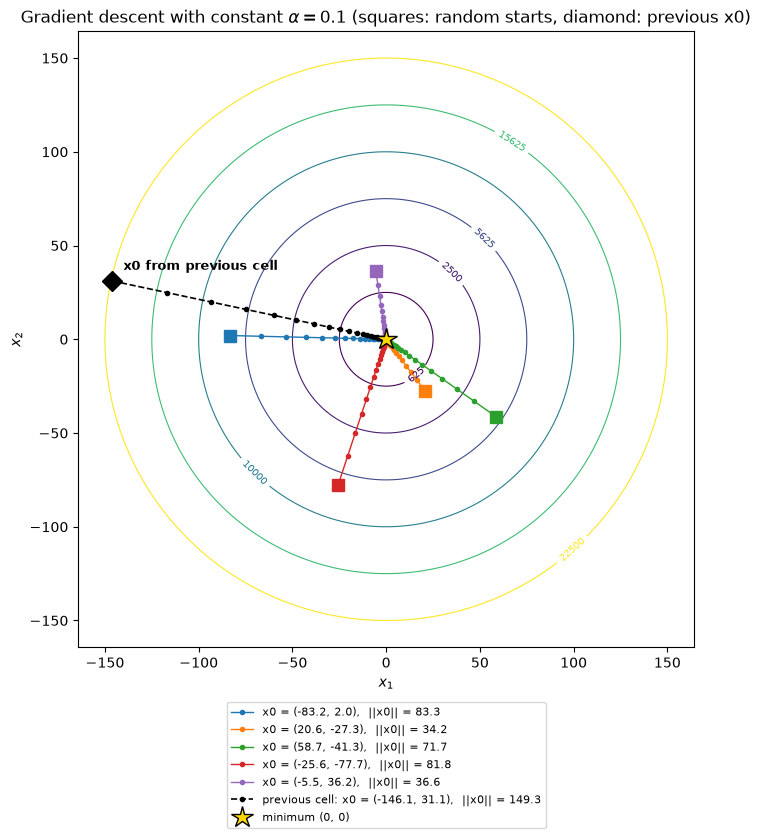

In [51]:
# MADE WITH AI

def grad_desc_path(grad_f, x0, alpha, max_iter):
    # Same iteration as grad_desc, but keeps every point to draw the trajectory
    x = x0
    path = [x]
    for i in range(max_iter):
        x = x - alpha * grad_f(x)
        path.append(x)
    return np.array(path)

# 5 random starting points at a distance between 30 and 100 from (0, 0)
r = np.random.uniform(30, 100, 5)
theta = np.random.uniform(0, 2*np.pi, 5)
starts = np.column_stack([r*np.cos(theta), r*np.sin(theta)])

# The x0 from the previous cell can be further away, so the plot limits adapt to it
lim = 1.1 * max(100, np.linalg.norm(x0))
step = 10 if lim <= 120 else 25

# Contour lines of f (circles of radius step, 2*step, ...)
X, Y = np.meshgrid(np.linspace(-lim, lim, 400), np.linspace(-lim, lim, 400))
Z = f(np.array([X, Y]))

fig, ax = plt.subplots(figsize=(8, 8))
cs = ax.contour(X, Y, Z, levels=[k**2 for k in np.arange(step, lim, step)], cmap="viridis", linewidths=0.8)
ax.clabel(cs, fontsize=7, fmt="%.0f")

colors = plt.cm.tab10.colors
for i, start in enumerate(starts):
    path = grad_desc_path(grad_f, start, alpha=0.1, max_iter=100)
    ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=3, lw=1,
            label=f"x0 = ({start[0]:.1f}, {start[1]:.1f}),  ||x0|| = {np.linalg.norm(start):.1f}")
    ax.plot(*start, "s", color=colors[i], ms=9)

# x0 from the previous cell, drawn in black with a dashed line and a diamond
path = grad_desc_path(grad_f, x0, alpha=0.1, max_iter=100)
ax.plot(path[:, 0], path[:, 1], "--o", color="k", ms=3, lw=1.2,
        label=f"previous cell: x0 = ({x0[0]:.1f}, {x0[1]:.1f}),  ||x0|| = {np.linalg.norm(x0):.1f}")
ax.plot(*x0, "D", color="k", ms=10)
ax.annotate("x0 from previous cell", x0, xytext=(8, 8), textcoords="offset points", fontsize=9, weight="bold")

ax.plot(0, 0, "*", color="gold", mec="k", ms=16, label="minimum (0, 0)")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title(r"Gradient descent with constant $\alpha = 0.1$ (squares: random starts, diamond: previous x0)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.show()

#### 1.1.2 Try gain with $\alpha^{k} = 1$ and $\alpha^{k} = 2$

In [52]:
print(f"Initial point: x0   = [{x0[0]:.4f}, {x0[1]:.4f}]")

x_final_1, f_final_1 = grad_desc(f, grad_f, x0, alpha=1, max_iter=100)

print("\n\nalpha = 1")
print(f"Final point:   x    = [{x_final_1[0]:.4f}, {x_final_1[1]:.4f}]")
print(f"Final value:   f(x) = {f_final_1:.4f}")

x_final_2, f_final_2 = grad_desc(f, grad_f, x0, alpha=2, max_iter=100)

print("\n\nalpha = 2")
print(f"Final point:   x    = [{x_final_2[0]:.2e}, {x_final_2[1]:.2e}]")
print(f"Final value:   f(x) = {f_final_2:.2e}")

Initial point: x0   = [-146.0721, 31.1098]


alpha = 1
Final point:   x    = [-146.0721, 31.1098]
Final value:   f(x) = 22304.8880


alpha = 2
Final point:   x    = [-7.53e+49, 1.60e+49]
Final value:   f(x) = 5.92e+99


In [53]:
# MADE WITH AI

# Distance from (0, 0) of every iterate, starting from the same x0 as in 1.1.1
path_1 = grad_desc_path(grad_f, x0, alpha=1, max_iter=100)
path_2 = grad_desc_path(grad_f, x0, alpha=2, max_iter=100)
dist_1 = np.linalg.norm(path_1, axis=1)
dist_2 = np.linalg.norm(path_2, axis=1)

print(f"{'k':>3} | {'x_k (alpha = 1)':>22} | {'||x_k|| (alpha = 1)':>20} | {'x_k (alpha = 2)':>26} | {'||x_k|| (alpha = 2)':>20}")
print("-" * 103)
for k, (p1, d1, p2, d2) in enumerate(zip(path_1, dist_1, path_2, dist_2)):
    point_1 = f"({p1[0]:.4f}, {p1[1]:.4f})"
    point_2 = f"({p2[0]:.4e}, {p2[1]:.4e})"
    print(f"{k:>3} | {point_1:>22} | {d1:>20.4f} | {point_2:>26} | {d2:>20.4e}")

  k |        x_k (alpha = 1) |  ||x_k|| (alpha = 1) |            x_k (alpha = 2) |  ||x_k|| (alpha = 2)
-------------------------------------------------------------------------------------------------------
  0 |   (-146.0721, 31.1098) |             149.3482 |  (-1.4607e+02, 3.1110e+01) |           1.4935e+02
  1 |   (146.0721, -31.1098) |             149.3482 |  (4.3822e+02, -9.3329e+01) |           4.4804e+02
  2 |   (-146.0721, 31.1098) |             149.3482 |  (-1.3146e+03, 2.7999e+02) |           1.3441e+03
  3 |   (146.0721, -31.1098) |             149.3482 |  (3.9439e+03, -8.3997e+02) |           4.0324e+03
  4 |   (-146.0721, 31.1098) |             149.3482 |  (-1.1832e+04, 2.5199e+03) |           1.2097e+04
  5 |   (146.0721, -31.1098) |             149.3482 |  (3.5496e+04, -7.5597e+03) |           3.6292e+04
  6 |   (-146.0721, 31.1098) |             149.3482 |  (-1.0649e+05, 2.2679e+04) |           1.0887e+05
  7 |   (146.0721, -31.1098) |             149.3482 |  (3.1946e+

Since $\nabla f(x) = 2x$, one step of gradient descent with constant $\alpha$ is
$$
    x^{k+1} = x^{k} - 2\alpha x^{k} = (1 - 2\alpha)\, x^{k}
    \quad\Longrightarrow\quad
    x^{k} = (1 - 2\alpha)^{k} x^{0}, \qquad \|x^{k}\| = |1 - 2\alpha|^{k}\, \|x^{0}\|
$$

- **$\alpha = 1$:** the factor is $1 - 2 = -1$, so $x^{k+1} = -x^{k}$. The iterates just bounce between $x^{0}$ and $-x^{0}$, and the distance to the minimum stays equal to $\|x^{0}\|$ in every iteration. The method never gets closer to $(0, 0)$.
- **$\alpha = 2$:** the factor is $1 - 4 = -3$, so the iterate changes sign and its distance to the minimum is multiplied by 3 in every iteration, the method diverges.

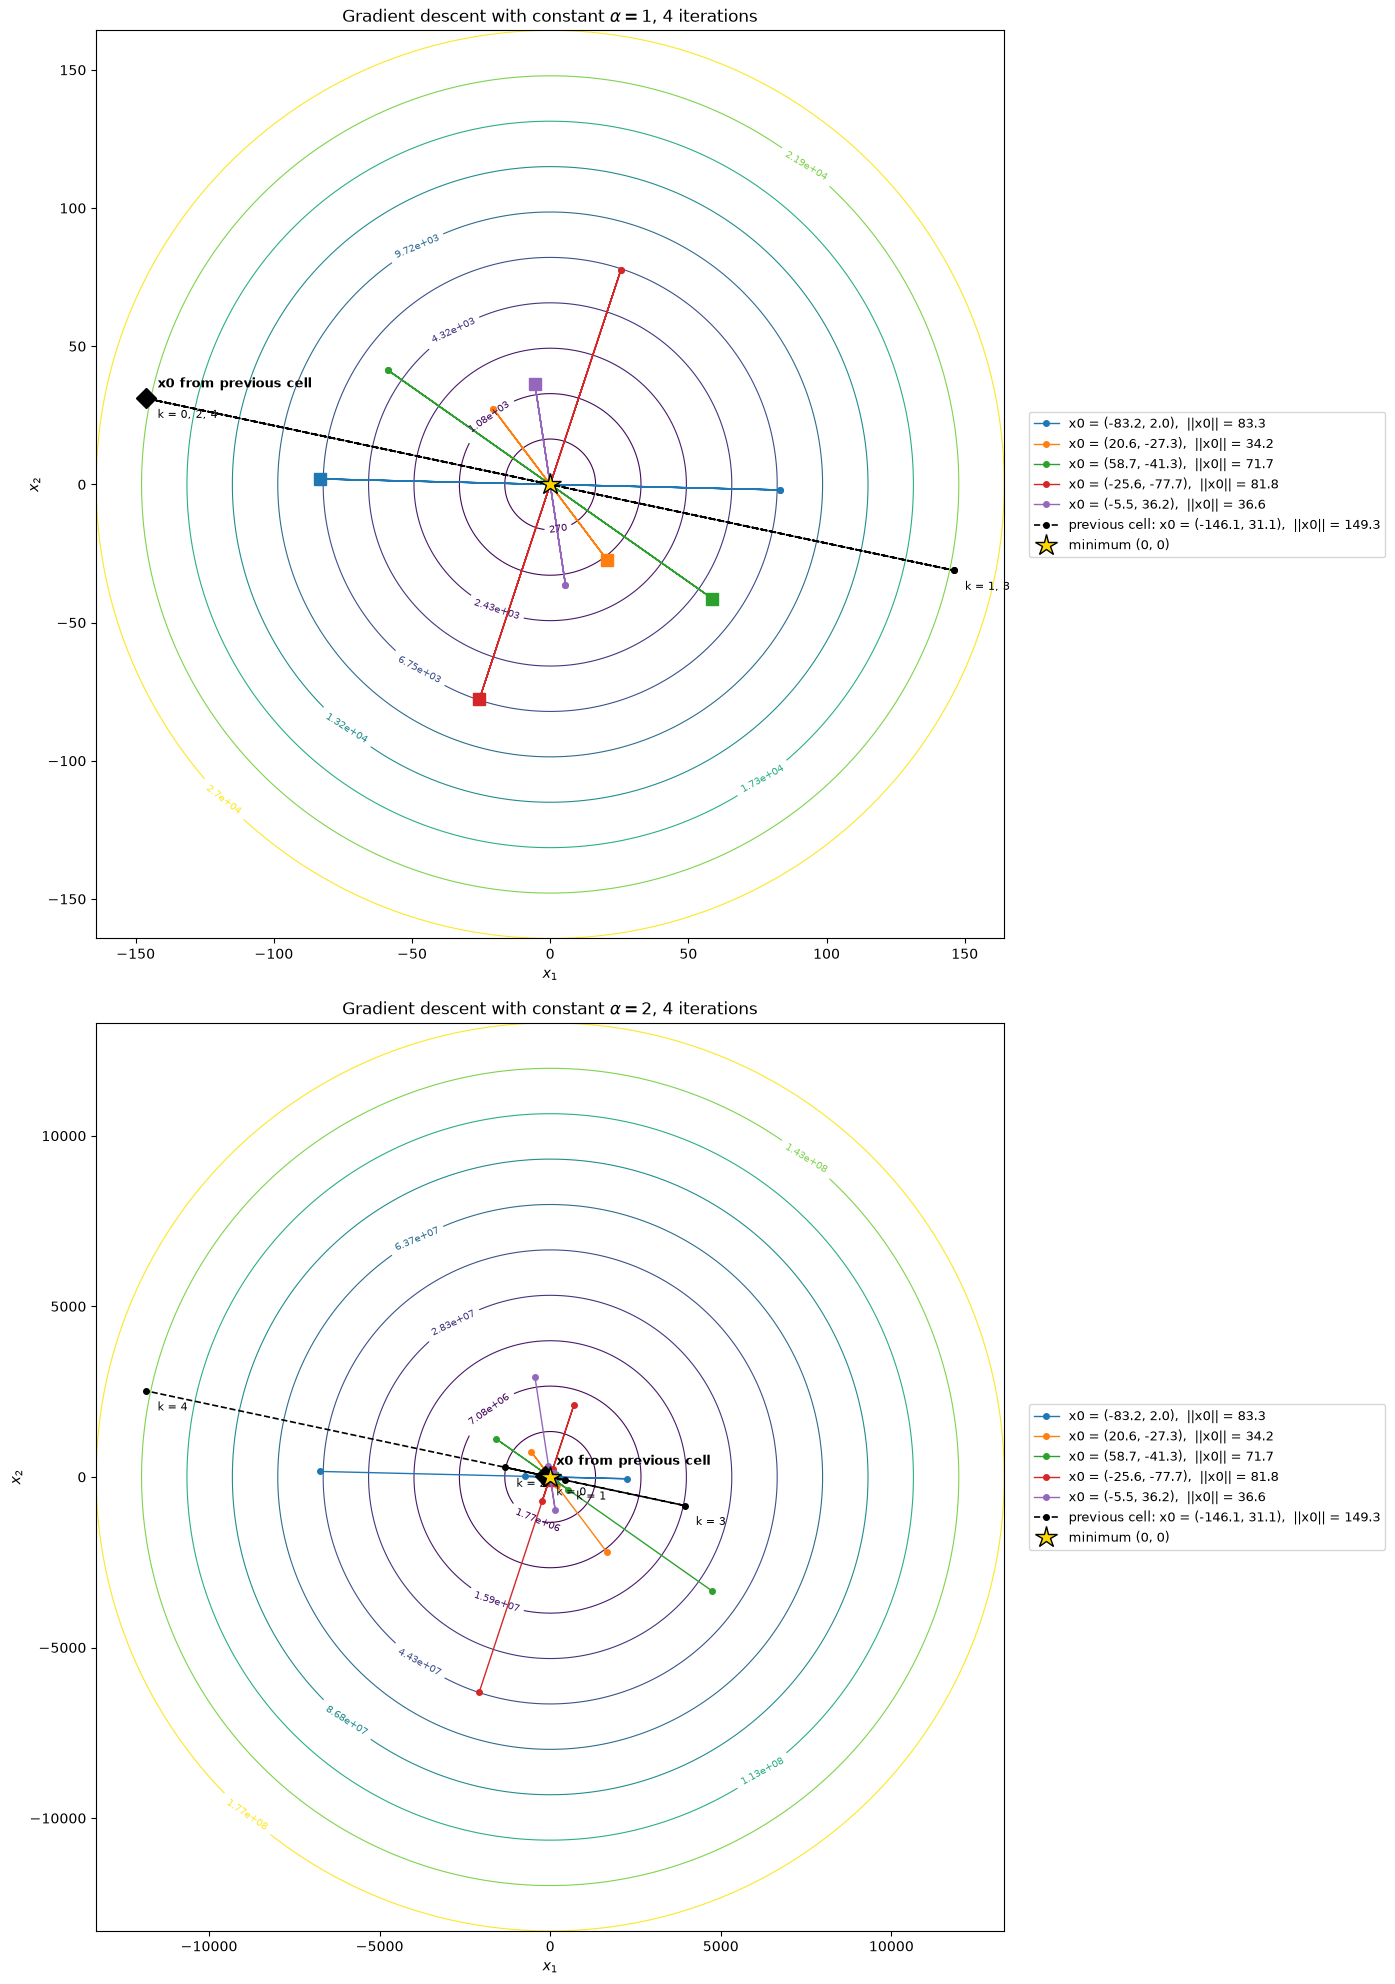

In [54]:
# MADE WITH AI

# Same plot as in 1.1.1 (same 5 random starts and x0 from cell 7), now with alpha = 1 and alpha = 2, 4 iterations
fig, axes = plt.subplots(2, 1, figsize=(12, 20))
colors = plt.cm.tab10.colors

for ax, alpha in zip(axes, [1, 2]):
    paths = [grad_desc_path(grad_f, start, alpha=alpha, max_iter=4) for start in starts]
    path_prev = grad_desc_path(grad_f, x0, alpha=alpha, max_iter=4)

    # Plot limits and contour lines adapt to how far the iterates go
    lim = 1.1 * max(np.linalg.norm(p, axis=1).max() for p in paths + [path_prev])
    X, Y = np.meshgrid(np.linspace(-lim, lim, 400), np.linspace(-lim, lim, 400))
    Z = f(np.array([X, Y]))
    cs = ax.contour(X, Y, Z, levels=np.linspace(0, lim, 11)[1:]**2, cmap="viridis", linewidths=0.8)
    ax.clabel(cs, fontsize=7, fmt="%.3g")

    for i, (start, path) in enumerate(zip(starts, paths)):
        ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=4, lw=1,
                label=f"x0 = ({start[0]:.1f}, {start[1]:.1f}),  ||x0|| = {np.linalg.norm(start):.1f}")
        ax.plot(*start, "s", color=colors[i], ms=9)

    # x0 from the previous cell, drawn in black with a dashed line and a diamond
    ax.plot(path_prev[:, 0], path_prev[:, 1], "--o", color="k", ms=4, lw=1.2,
            label=f"previous cell: x0 = ({x0[0]:.1f}, {x0[1]:.1f}),  ||x0|| = {np.linalg.norm(x0):.1f}")
    ax.plot(*x0, "D", color="k", ms=10)
    ax.annotate("x0 from previous cell", x0, xytext=(8, 8), textcoords="offset points", fontsize=9, weight="bold")

    # Iteration number of each point of the black path (points that coincide share one label)
    labels = {}
    for k, p in enumerate(path_prev):
        labels.setdefault(tuple(np.round(p, 6)), []).append(str(k))
    for p, ks in labels.items():
        ax.annotate("k = " + ", ".join(ks), p, xytext=(8, -14), textcoords="offset points", fontsize=8)

    ax.plot(0, 0, "*", color="gold", mec="k", ms=16, label="minimum (0, 0)")
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(rf"Gradient descent with constant $\alpha = {alpha}$, 4 iterations")
    ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()
plt.show()

### 1.2 A function with multiple minima

We will now define $f$ as:
$$
    f(x) = x_{1}^{2}\left(4 - 2.1x_{1}^{2} + \tfrac{1}{3}x_{1}^{4}\right) + x_{1}x_{2} + x_{2}^{2}\left(-4 + 4x_{2}^{2}\right)
$$

By derivating, we obtain the gradient:
$$
    \nabla f(x) = \left(8x_{1} - 8.4x_{1}^{3} + 2x_{1}^{5} + x_{2},\; x_{1} - 8x_{2} + 16x_{2}^{3}\right)
$$

and the Hessian:
$$
    \nabla^{2} f(x) = \begin{pmatrix} 8 - 25.2x_{1}^{2} + 10x_{1}^{4} & 1 \\ 1 & -8 + 48x_{2}^{2} \end{pmatrix}
$$


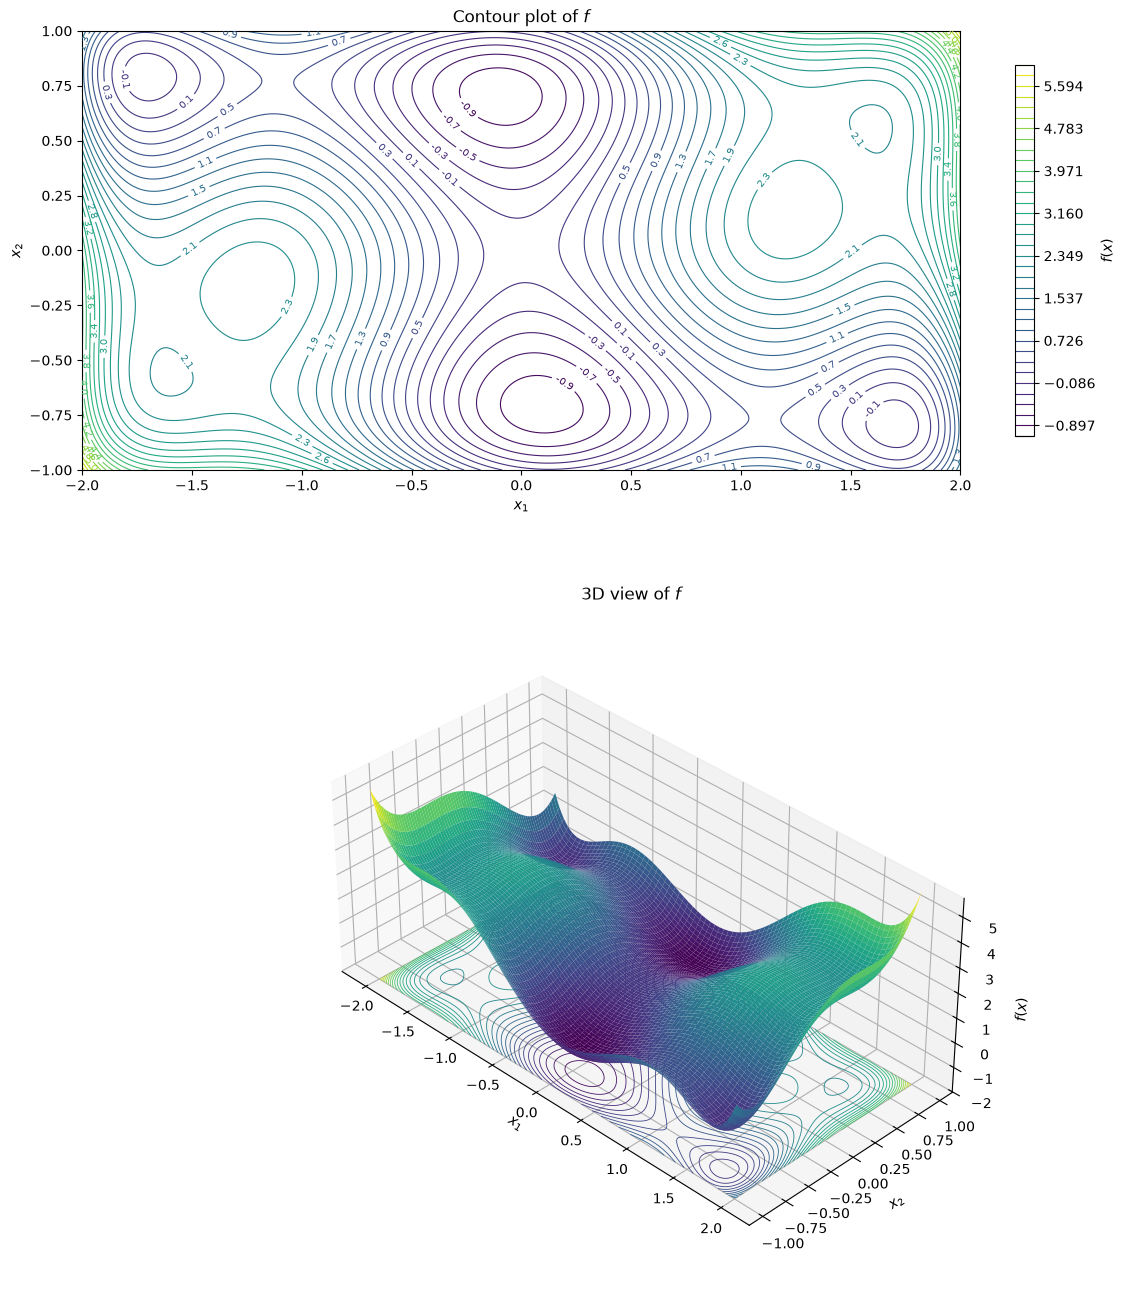

In [55]:
# PLOT MADE WITH THE HELP OF AI

def f_mm(x):
    return x[0]**2 * (4 - 2.1*x[0]**2 + x[0]**4/3) + x[0]*x[1] + x[1]**2 * (-4 + 4*x[1]**2)

def grad_f_mm(x):
    return np.array([8*x[0] - 8.4*x[0]**3 + 2*x[0]**5 + x[1],
                     x[0] - 8*x[1] + 16*x[1]**3])

# The six minima of f (first two rows: global, f = -1.0316; the rest: local)
minima = np.array([[-0.0898,  0.7127], [ 0.0898, -0.7127],
                   [ 1.7036, -0.7961], [-1.7036,  0.7961],
                   [ 1.6071,  0.5687], [-1.6071, -0.5687]])

# Grid in x1 in [-2, 2], x2 in [-1, 1]
X1, X2 = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-1, 1, 400))
Z_mm = f_mm(np.array([X1, X2]))
levels_mm = np.linspace(-1.1, 6, 36)

def contour_mm(ax, show_minima=True):
    # Contour lines of f, reused by the plots of this section
    cs = ax.contour(X1, X2, Z_mm, levels=levels_mm, cmap="viridis", linewidths=0.8)
    if show_minima:
        ax.plot(minima[:2, 0], minima[:2, 1], "*", color="gold", mec="k", ms=16, label="global minima")
        ax.plot(minima[2:, 0], minima[2:, 1], "*", color="silver", mec="k", ms=12, label="local minima")
    ax.set_xlim(-2, 2); ax.set_ylim(-1, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    return cs

fig = plt.figure(figsize=(12, 14))

# Contour plot
ax = fig.add_subplot(2, 1, 1)
cs = contour_mm(ax, show_minima=False)
ax.clabel(cs, fontsize=7, fmt="%.1f")
fig.colorbar(cs, ax=ax, label="$f(x)$", shrink=0.55)
ax.set_title("Contour plot of $f$")

# 3D view
ax3d = fig.add_subplot(2, 1, 2, projection="3d")
ax3d.plot_surface(X1, X2, Z_mm, cmap="viridis", rstride=5, cstride=5, linewidth=0, antialiased=True)
ax3d.contour(X1, X2, Z_mm, levels=levels_mm, cmap="viridis", linewidths=0.6, offset=Z_mm.min() - 1)
ax3d.set_zlim(Z_mm.min() - 1, Z_mm.max())
ax3d.set_xlabel("$x_1$"); ax3d.set_ylabel("$x_2$"); ax3d.set_zlabel("$f(x)$")
ax3d.set_box_aspect((2, 1, 0.8))
ax3d.view_init(elev=35, azim=-45)
ax3d.set_title("3D view of $f$")

plt.tight_layout()
plt.show()

#### 1.2.1 Gradient descent with a constant $\alpha^{k} = 0.1$ from different starting points

                x0 |   x after 100 iterations |     f(x) | ||grad f(x)||
--------------------------------------------------------------------------
 (-1.5000, 0.8000) |        (-1.6221, 0.9095) |   0.0110 |    3.4065e+00
 (1.5000, -0.8000) |        (1.6221, -0.9095) |   0.0110 |    3.4065e+00
  (0.5000, 0.5000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
(-0.5000, -0.5000) |        (0.0898, -0.7127) |  -1.0316 |    1.7902e-15
  (1.0000, 0.9000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
(-1.9000, -0.9000) |        (0.0898, -0.7127) |  -1.0316 |    1.7902e-15
  (1.9000, 0.2000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
 (-1.0000, 0.0000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
  (1.4000, 0.3000) |         (1.6071, 0.5687) |   2.1043 |    1.8310e-15


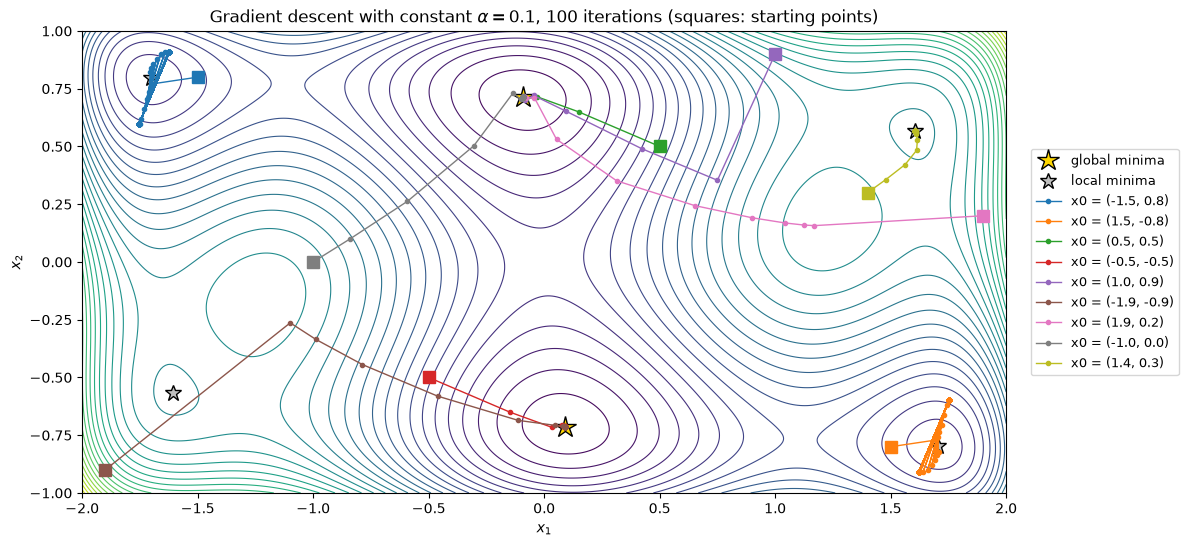

In [56]:
# MADE WITH AI

# Starting points spread over the box, the same ones are used in 1.2.2
starts_mm = np.array([[-1.5,  0.8], [ 1.5, -0.8], [ 0.5,  0.5], [-0.5, -0.5],
                      [ 1.0,  0.9], [-1.9, -0.9], [ 1.9,  0.2], [-1.0,  0.0],
                      [ 1.4,  0.3]])

paths_const = [grad_desc_path(grad_f_mm, x0_mm, alpha=0.1, max_iter=100) for x0_mm in starts_mm]

print(f"{'x0':>18} | {'x after 100 iterations':>24} | {'f(x)':>8} | {'||grad f(x)||':>13}")
print("-" * 74)
for x0_mm, path in zip(starts_mm, paths_const):
    x = path[-1]
    print(f"{f'({x0_mm[0]:.4f}, {x0_mm[1]:.4f})':>18} | {f'({x[0]:.4f}, {x[1]:.4f})':>24} | "
          f"{f_mm(x):>8.4f} | {np.linalg.norm(grad_f_mm(x)):>13.4e}")

fig, ax = plt.subplots(figsize=(12, 6))
contour_mm(ax)
colors = plt.cm.tab10.colors
for i, (x0_mm, path) in enumerate(zip(starts_mm, paths_const)):
    ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=3, lw=1,
            label=f"x0 = ({x0_mm[0]:.1f}, {x0_mm[1]:.1f})")
    ax.plot(*x0_mm, "s", color=colors[i], ms=9)
ax.set_title(r"Gradient descent with constant $\alpha = 0.1$, 100 iterations (squares: starting points)")
ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

Conclusions

- Most starting points converge to the minimum of their valley. Only 2 strating points, after 100 iterations, don't reach their minimum as they don't converge. Of the 7, 5 ended up in their "valley's minimum", the ones that didn't did a first step that was too big and moved to another valley.

- From $(\pm 1.5, \mp 0.8)$ the method does not converge. The iterates end up jumping between two points around the local minimum $(-1.7036, 0.7961)$, with $\|\nabla f\| \approx 3.4$ after 100 iterations. This is the same problem as with $\alpha = 1$ in 1.1.2. In other words, the valley of $(\pm 1.7036, \mp 0.7961)$ is too steep for $\alpha = 0.1$. Every step overshoots the minimum.

#### 1.2.2 Gradient descent with backtracking

In the first iteration we start with $\alpha = 0.1$ and halve it until $f(x^{k} - \alpha\nabla f(x^{k})) < f(x^{k})$. Then we update $x^{k+1} = x^{k} - \alpha\nabla f(x^{k})$. The value of $\alpha$ is not reset at every iteration: the one accepted in iteration $k$ is the starting value for iteration $k+1$, so $\alpha$ can only decrease. Instead of a fixed number of iterations, we stop when $\|\nabla f(x^{k})\| < 10^{-5}$ (with at most 100 iterations). To compare both methods fairly, we also run the constant step $\alpha = 0.1$ with the same stopping criterion, from the same starting points as in 1.2.1.

Stopping criterion: ||grad f(x)|| < 1e-5 (at most 100 iterations)

                x0 |         constant alpha = 0.1         |                  backtracking                 
                   | iterations |                 final x | iterations | halvings |                final x
----------------------------------------------------------------------------------------------------------
 (-1.5000, 0.8000) |       >100 |       (-1.6221, 0.9095) |          7 |        1 |      (-1.7036, 0.7961)
 (1.5000, -0.8000) |       >100 |       (1.6221, -0.9095) |          7 |        1 |      (1.7036, -0.7961)
  (0.5000, 0.5000) |         25 |       (-0.0898, 0.7127) |         25 |        0 |      (-0.0898, 0.7127)
(-0.5000, -0.5000) |         25 |       (0.0898, -0.7127) |         25 |        0 |      (0.0898, -0.7127)
  (1.0000, 0.9000) |         28 |       (-0.0898, 0.7127) |         28 |        0 |      (-0.0898, 0.7127)
(-1.9000, -0.9000) |         19 |       (0.0898, -0.7127) |         19 |     

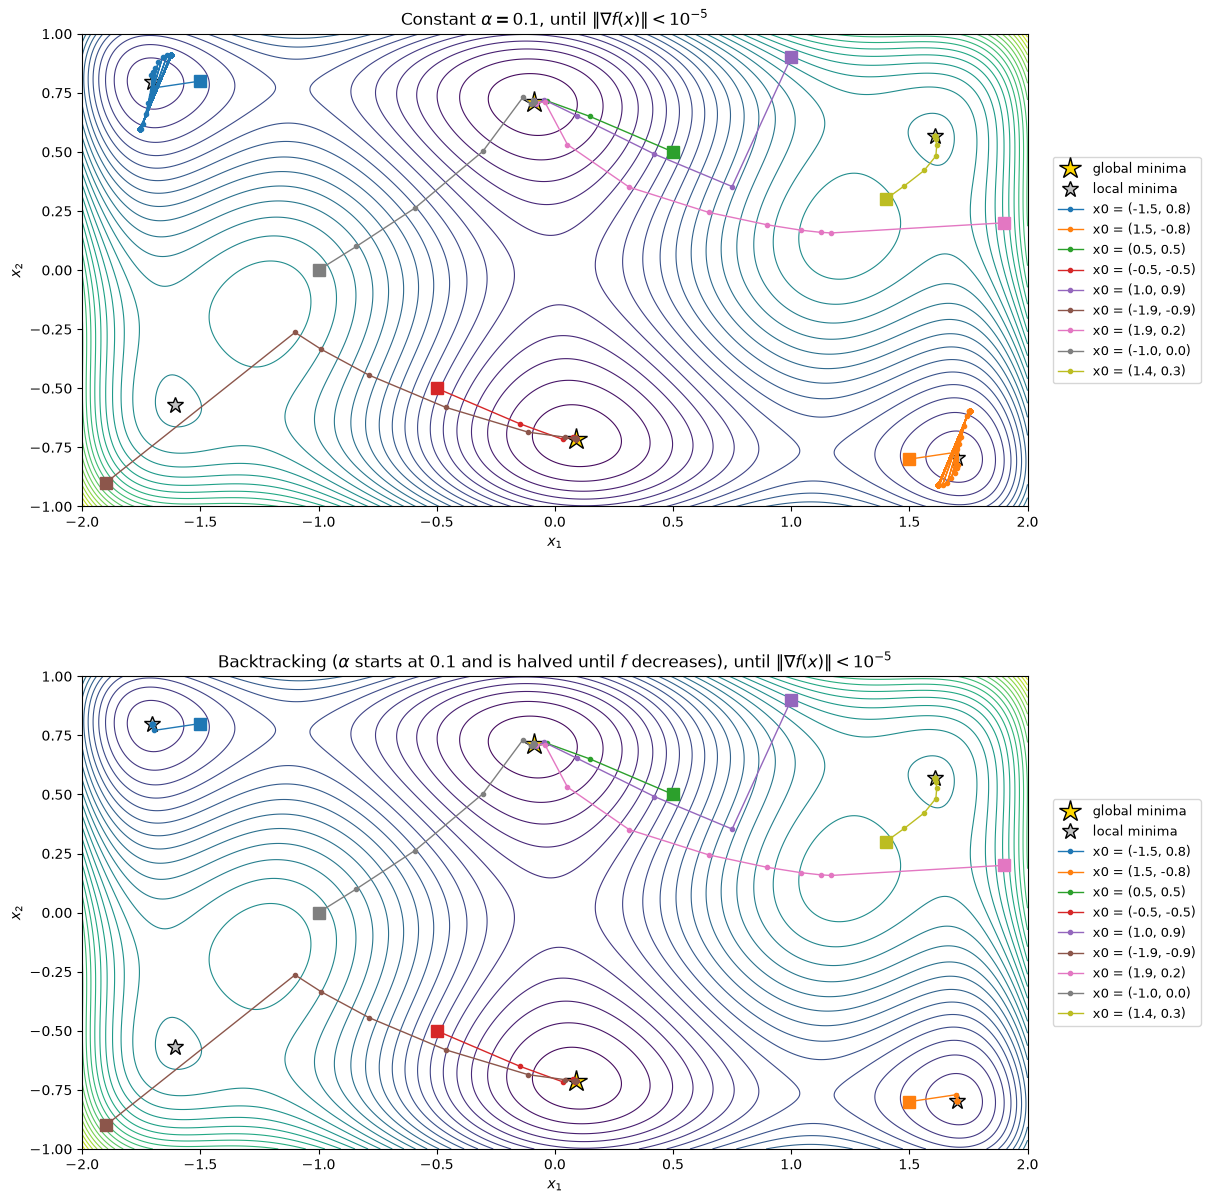

In [57]:
# PLOTTING (AND NECESSARY EDITS TO THE FUNCTIONS) MADE WITH THE HELP OF AI

def grad_desc_backtracking(f, grad_f, x0, alpha=0.1, tol=1e-5, max_iter=100, alpha_min=1e-5):
    x = x0
    path = [x]
    alphas = []
    n_halvings = 0
    for k in range(max_iter):
        grad = grad_f(x)
        if np.linalg.norm(grad) < tol:
            break
        while f(x - alpha * grad) >= f(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        x = x - alpha * grad
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings

def grad_desc_tol(grad_f, x0, alpha=0.1, tol=1e-5, max_iter=100):
    x = x0
    path = [x]
    for k in range(max_iter):
        if np.linalg.norm(grad_f(x)) < tol:
            break
        x = x - alpha * grad_f(x)
        path.append(x)
    return np.array(path)

results_bt = [grad_desc_backtracking(f_mm, grad_f_mm, x0_mm) for x0_mm in starts_mm]
paths_tol = [grad_desc_tol(grad_f_mm, x0_mm, alpha=0.1) for x0_mm in starts_mm]

print("Stopping criterion: ||grad f(x)|| < 1e-5 (at most 100 iterations)\n")
print(f"{'x0':>18} | {'constant alpha = 0.1':^36} | {'backtracking':^46}")
print(f"{'':>18} | {'iterations':>10} | {'final x':>23} | {'iterations':>10} | {'halvings':>8} | {'final x':>22}")
print("-" * 106)
for x0_mm, p_tol, (p_bt, alphas, n_halv) in zip(starts_mm, paths_tol, results_bt):
    it_tol = len(p_tol) - 1
    it_tol = f"{it_tol}" if np.linalg.norm(grad_f_mm(p_tol[-1])) < 1e-5 else f">{it_tol}"
    print(f"{f'({x0_mm[0]:.4f}, {x0_mm[1]:.4f})':>18} | {it_tol:>10} | {f'({p_tol[-1][0]:.4f}, {p_tol[-1][1]:.4f})':>23} | "
          f"{len(p_bt) - 1:>10} | {n_halv:>8} | {f'({p_bt[-1][0]:.4f}, {p_bt[-1][1]:.4f})':>22}")

fig, axes = plt.subplots(2, 1, figsize=(12, 13))
for ax, paths, title in zip(axes, [paths_tol, [r[0] for r in results_bt]],
                            [r"Constant $\alpha = 0.1$", r"Backtracking ($\alpha$ starts at 0.1 and is halved until $f$ decreases)"]):
    contour_mm(ax)
    for i, (x0_mm, path) in enumerate(zip(starts_mm, paths)):
        ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=3, lw=1,
                label=f"x0 = ({x0_mm[0]:.1f}, {x0_mm[1]:.1f})")
        ax.plot(*x0_mm, "s", color=colors[i], ms=9)
    ax.set_title(title + r", until $\|\nabla f(x)\| < 10^{-5}$")
    ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

Conclusions

- The points that converged with $\alpha$ constant still converge in the same number of steps, this makes sense as they weren't getting stuck.
- The points that didn't converge now do. From $(\pm 1.5, \mp 0.8)$ with $\alpha = 0.1$ got stuck jumping between two points, now, by halving $\alpha$ they converge and in very few steps as the starting points are already close to their minimum.
- The problem of starting points missing their "valley's minimum" still persists as the first step is still too large to end in their valley.

### 1.3 The Rosenbrock function

We will now define $f$ as:
$$
    f(x) = (a - x_{1})^{2} + b\,(x_{2} - x_{1}^{2})^{2}, \qquad a = 1,\; b = 100
$$

By derivating, we obtain the gradient:
$$
    \nabla f(x) = \left(-2(a - x_{1}) - 4b\,x_{1}(x_{2} - x_{1}^{2}),\; 2b\,(x_{2} - x_{1}^{2})\right)
$$

The only minimum is at $(x_{1}^{*}, x_{2}^{*}) = (a, a^{2}) = (1, 1)$, where $f = 0$, since both terms of $f$ are squares and vanish there. It lies at the bottom of a long, narrow and curved valley.

#### 1.3.1 Contour plot of the Rosenbrock function with the gradient

In [ ]:
a, b = 1, 100

def f_rosen(x): return (a - x[0])**2 + b * (x[1] - x[0]**2)**2
def grad_f_rosen(x):
    return np.array([-2*(a - x[0]) - 4*b*x[0]*(x[1] - x[0]**2),
                     2*b*(x[1] - x[0]**2)])

x = np.array([-1.2, 1.0]); h = 1e-6
num = np.array([(f_rosen(x + h*e) - f_rosen(x - h*e)) / (2*h) for e in np.eye(2)])
print("analytical gradient:", grad_f_rosen(x))
print("numerical gradient: ", num)

analytical gradient: [-215.6  -88. ]
numerical gradient:  [-215.59999998  -88.        ]


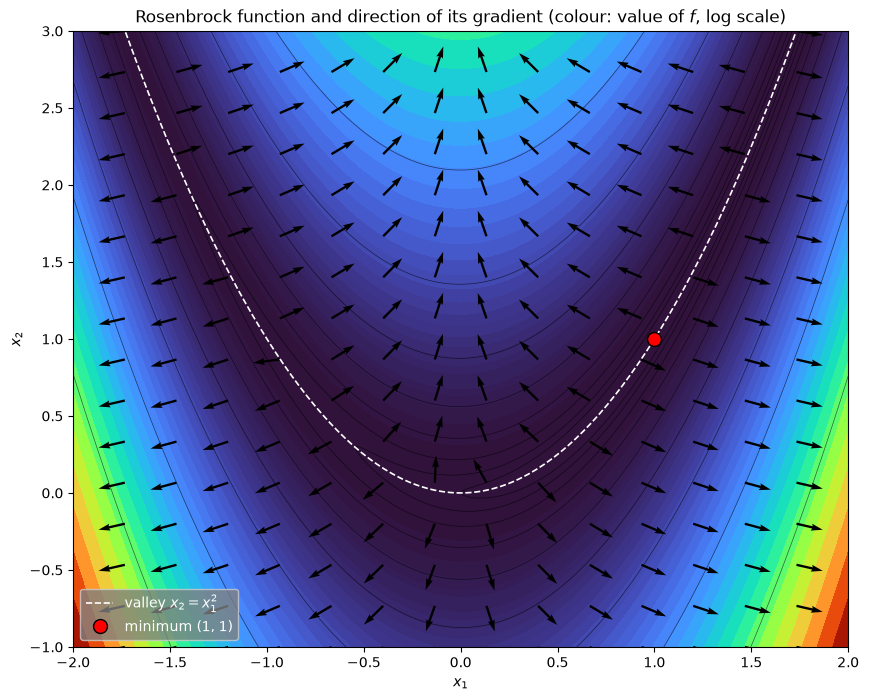

In [59]:
# PLOT MADE WITH THE HELP OF AI

X1r, X2r = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-1, 3, 400))
Z_r = f_rosen(np.array([X1r, X2r]))

fig, ax = plt.subplots(figsize=(10, 8))
# Background colour = value of f (dark = small f, red = large f).
# f grows very fast away from the valley, so the levels are spaced geometrically; everything below f = 1 is the darkest colour
ax.contourf(X1r, X2r, Z_r, levels=np.geomspace(1, Z_r.max(), 60), cmap="turbo", extend="min")
# A few contour lines on top
ax.contour(X1r, X2r, Z_r, levels=np.geomspace(1, Z_r.max(), 10), colors="k", linewidths=0.5, alpha=0.6)

# Gradient on a coarse grid. Its length changes by orders of magnitude, so we only draw its direction
xg, yg = np.meshgrid(np.linspace(-2, 2, 16), np.linspace(-1, 3, 16))
G = grad_f_rosen(np.array([xg, yg]))
norm = np.hypot(G[0], G[1])
ax.quiver(xg, yg, G[0]/norm, G[1]/norm, color="k", angles="xy", width=0.003)

xs = np.linspace(-2, 2, 200)
ax.plot(xs, xs**2, "w--", lw=1.2, label="valley $x_2 = x_1^2$")
ax.plot(1, 1, "o", color="red", mec="k", ms=10, label="minimum (1, 1)")
ax.set_xlim(-2, 2); ax.set_ylim(-1, 3)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Rosenbrock function and direction of its gradient (colour: value of $f$, log scale)")
ax.legend(loc="lower left", facecolor="gray", labelcolor="white")
plt.show()

#### 1.3.2 Gradient descent with backtracking from different starting points

We use the same backtracking algorithm as in 1.2.2 (`grad_desc_backtracking`): $\alpha$ starts at 0.1, is halved until $f$ decreases and is not reset between iterations. This time we do not limit the iterations to 100, we stop when $\|\nabla f(x^{k})\| < 10^{-5}$ (we only keep a cap of 1000000 iterations in case it never stops). We try six starting points and check how close the last point is to the minimum $(1, 1)$.

After that, we also look at what would have happened with the other criterion of the statement, $|f(x^{k+1}) - f(x^{k})| < 10^{-3}$, using the same runs.

In [60]:
starts_r = np.array([[-1.2, 1.0], [-1.5, 2.0], [0.0, 0.0], [2.0, 2.0], [-1.0, -0.5], [0.0, 2.0]])
x_star = np.array([1.0, 1.0])

# AI recommended a max_iter = 1000000, just in case
results_r = [grad_desc_backtracking(f_rosen, grad_f_rosen, x0, tol=1e-5, max_iter=1000000) for x0 in starts_r]

print("Stopping criterion: ||grad f(x)|| < 1e-5\n")
print(f"{'x0':>14} | {'iterations':>10} | {'halvings':>8} | {'final x':>20} | {'f(x)':>9} | {'||grad f(x)||':>13}")
print("-" * 85)
for x0, (path, alphas, n_halv) in zip(starts_r, results_r):
    x = path[-1]
    print(f"{f'({x0[0]:.1f}, {x0[1]:.1f})':>14} | {len(path) - 1:>10} | {n_halv:>8} | {f'({x[0]:.5f}, {x[1]:.5f})':>20} | "
          f"{f_rosen(x):>9.2e} | {np.linalg.norm(grad_f_rosen(x)):>13.2e}")

# What would have happened with the other criterion of the statement, |f(x_{k+1}) - f(x_k)| < 1e-3?
# We look for the first iteration k of the same runs in which it is satisfied and stop there.
# In grad_desc_backtracking alpha starts at 0.1 and is only ever halved (it is not reset at every iteration),
# so the alpha accepted at iteration k is 0.1 / 2^(halvings up to k)
print("\nStopping criterion: |f(x_{k+1}) - f(x_k)| < 1e-3 (first iteration where it holds)\n")
print(f"{'x0':>14} | {'iterations':>10} | {'halvings':>8} | {'final x':>20} | {'f(x)':>9} | {'||grad f(x)||':>13}")
print("-" * 85)
for x0, (path, alphas, n_halv) in zip(starts_r, results_r):
    f_path = np.array([f_rosen(p) for p in path])
    k = np.argmax(np.abs(np.diff(f_path)) < 1e-3) + 1
    x = path[k]
    halv_k = int(round(np.log2(0.1 / alphas[k - 1])))
    print(f"{f'({x0[0]:.1f}, {x0[1]:.1f})':>14} | {k:>10} | {halv_k:>8} | {f'({x[0]:.5f}, {x[1]:.5f})':>20} | "
          f"{f_rosen(x):>9.2e} | {np.linalg.norm(grad_f_rosen(x)):>13.2e}")

Stopping criterion: ||grad f(x)|| < 1e-5

            x0 | iterations | halvings |              final x |      f(x) | ||grad f(x)||
-------------------------------------------------------------------------------------
   (-1.2, 1.0) |      36586 |        7 |   (1.00001, 1.00002) |  1.25e-10 |      1.00e-05
   (-1.5, 2.0) |      34470 |        7 |   (0.99999, 0.99998) |  1.25e-10 |      1.00e-05
    (0.0, 0.0) |      15616 |        6 |   (0.99999, 0.99998) |  1.25e-10 |      1.00e-05
    (2.0, 2.0) |      35731 |        7 |   (1.00001, 1.00002) |  1.25e-10 |      1.00e-05
  (-1.0, -0.5) |      15544 |        6 |   (0.99999, 0.99998) |  1.25e-10 |      1.00e-05
    (0.0, 2.0) |      15607 |        6 |   (0.99999, 0.99998) |  1.25e-10 |      1.00e-05

Stopping criterion: |f(x_{k+1}) - f(x_k)| < 1e-3 (first iteration where it holds)

            x0 | iterations | halvings |              final x |      f(x) | ||grad f(x)||
--------------------------------------------------------------------

With the first criterion, we see that all 6 points end up reaching the minimum but take a long time to reach it, with very little halving, 6 or 7 in total, as $\alpha$ is only halved at the beginning and then it stays constant.

On the other hand, we see that with the second criterion, as convergence is difficult in this function, all the sequences halted before getting close to the minimum: the gradient is bigger than 0.3 and the points are far from $(1, 1)$. It is also interesting to see how much faster they reached the stopping criterion compared to the first one, consequently, with the same or fewer halvings (4 to 7).

Now we try again with a stopping criterion of $\left| f(x_{k+1}) - f(x_{k}) \right| < 10^{-8}$

In [68]:
print("\nStopping criterion: |f(x_{k+1}) - f(x_k)| < 1e-8 (first iteration where it holds)\n")
print(f"{'x0':>14} | {'iterations':>10} | {'halvings':>8} | {'final x':>20} | {'f(x)':>9} | {'||grad f(x)||':>13}")
print("-" * 85)
for x0, (path, alphas, n_halv) in zip(starts_r, results_r):
    f_path = np.array([f_rosen(p) for p in path])
    k = np.argmax(np.abs(np.diff(f_path)) < 1e-8) + 1
    x = path[k]
    halv_k = int(round(np.log2(0.1 / alphas[k - 1])))
    print(f"{f'({x0[0]:.1f}, {x0[1]:.1f})':>14} | {k:>10} | {halv_k:>8} | {f'({x[0]:.5f}, {x[1]:.5f})':>20} | "
          f"{f_rosen(x):>9.2e} | {np.linalg.norm(grad_f_rosen(x)):>13.2e}")


Stopping criterion: |f(x_{k+1}) - f(x_k)| < 1e-8 (first iteration where it holds)

            x0 | iterations | halvings |              final x |      f(x) | ||grad f(x)||
-------------------------------------------------------------------------------------
   (-1.2, 1.0) |      17714 |        7 |   (1.00401, 1.00805) |  1.61e-05 |      3.58e-03
   (-1.5, 2.0) |      15658 |        7 |   (0.99601, 0.99203) |  1.59e-05 |      3.58e-03
    (0.0, 0.0) |       6763 |        6 |   (0.99718, 0.99436) |  7.96e-06 |      2.53e-03
    (2.0, 2.0) |      16858 |        7 |   (1.00401, 1.00806) |  1.61e-05 |      3.58e-03
  (-1.0, -0.5) |       6691 |        6 |   (0.99718, 0.99436) |  7.96e-06 |      2.53e-03
    (0.0, 2.0) |       6754 |        6 |   (0.99718, 0.99436) |  7.96e-06 |      2.53e-03


With this much stricter stopping crierion, the succession halted much closer to $(1,1)$. But still is not as close as the other criterion. Which makes sense as this criterion is easier to proc when the slope is almost flat.

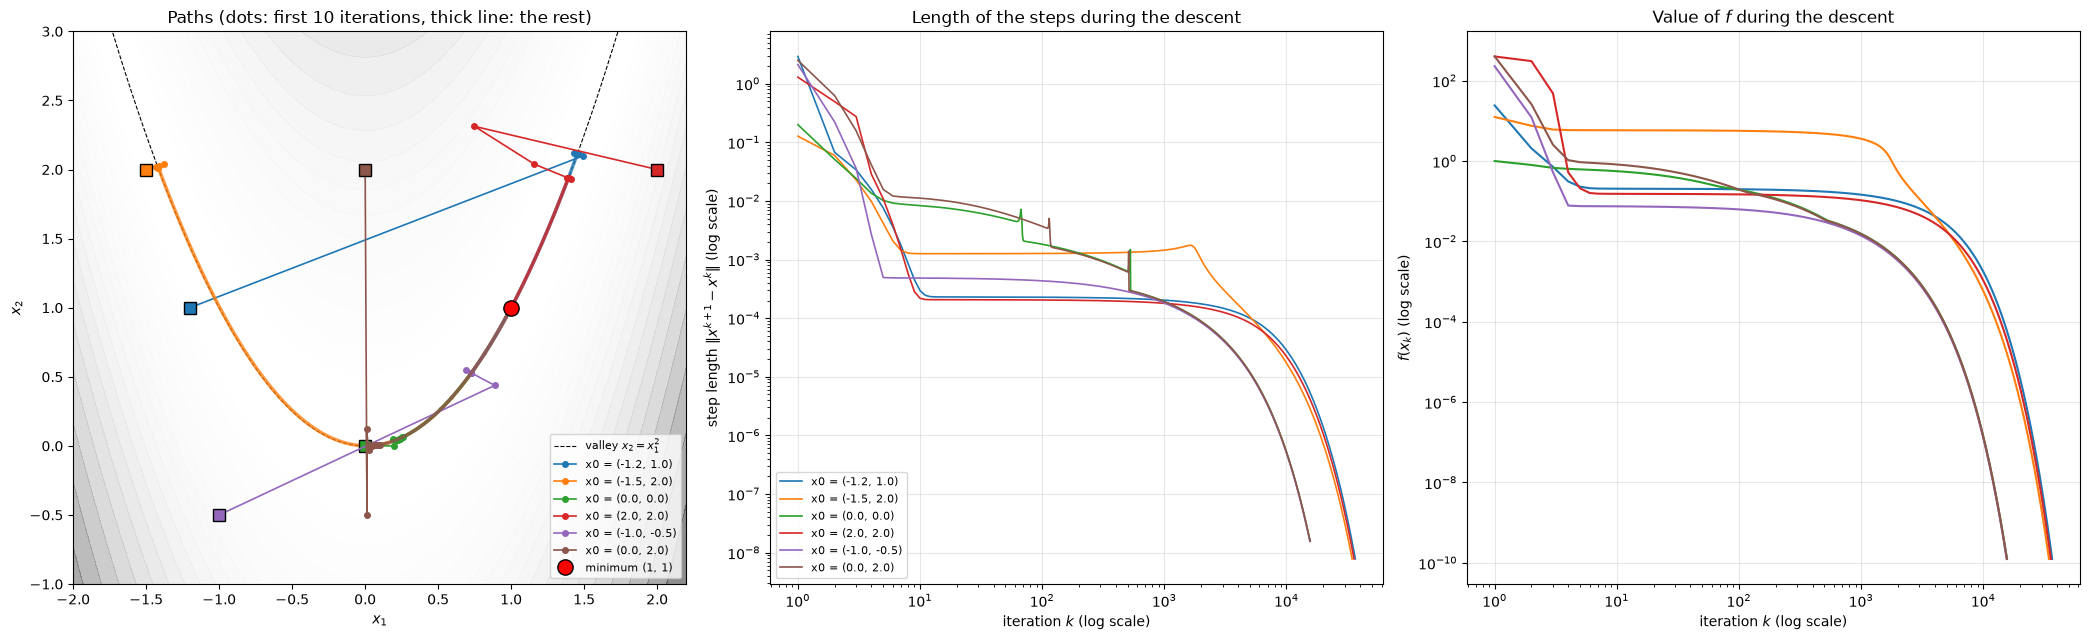

In [62]:
# PLOT MADE WITH THE HELP OF AI

colors = plt.cm.tab10.colors
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))

# 1) Paths of the six runs. The dots mark the first 10 iterations (long jumps), the line is the rest of the path
X1p, X2p = np.meshgrid(np.linspace(-2, 2.2, 400), np.linspace(-1, 3, 400))
Z_p = f_rosen(np.array([X1p, X2p]))
axes[0].contourf(X1p, X2p, Z_p, levels=np.geomspace(1, Z_p.max(), 40), cmap="Greys", alpha=0.5, extend="min")
xs = np.linspace(-2, 2.2, 200)
axes[0].plot(xs, xs**2, "k--", lw=0.8, label="valley $x_2 = x_1^2$")
for i, (x0, (path, alphas, n_halv)) in enumerate(zip(starts_r, results_r)):
    axes[0].plot(path[:11, 0], path[:11, 1], "-o", color=colors[i], lw=1.2, ms=4,
                 label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f})")
    axes[0].plot(path[10:, 0], path[10:, 1], "-", color=colors[i], lw=2.5, alpha=0.8)
    axes[0].plot(*x0, "s", color=colors[i], mec="k", ms=9)
axes[0].plot(1, 1, "o", color="red", mec="k", ms=11, label="minimum (1, 1)")
axes[0].set_xlim(-2, 2.2); axes[0].set_ylim(-1, 3)
axes[0].set_xlabel("$x_1$"); axes[0].set_ylabel("$x_2$")
axes[0].set_title("Paths (dots: first 10 iterations, thick line: the rest)")
axes[0].legend(fontsize=8, loc="lower right")

# 2) Length of the step ||x_{k+1} - x_k|| at every iteration: long jumps at the beginning, tiny steps afterwards
for i, (x0, (path, alphas, n_halv)) in enumerate(zip(starts_r, results_r)):
    step_len = np.linalg.norm(np.diff(path, axis=0), axis=1)
    axes[1].loglog(np.arange(1, len(step_len) + 1), step_len, color=colors[i], lw=1.2,
                   label=f"x0 = ({x0[0]:.1f}, {x0[1]:.1f})")
axes[1].set_xlabel("iteration $k$ (log scale)")
axes[1].set_ylabel(r"step length $\|x^{k+1} - x^{k}\|$ (log scale)")
axes[1].set_title("Length of the steps during the descent")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8, loc="lower left")

# 3) Value of f along the iterations
for i, (x0, (path, alphas, n_halv)) in enumerate(zip(starts_r, results_r)):
    axes[2].loglog(np.arange(1, len(path) + 1), [f_rosen(p) for p in path], color=colors[i])
axes[2].set_xlabel("iteration $k$ (log scale)"); axes[2].set_ylabel("$f(x_k)$ (log scale)")
axes[2].set_title("Value of $f$ during the descent")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Conclusions**

- **It reaches the minimum, but it needs a huge number of iterations.** From the six starting points the algorithm stops after 15544 to 36586 iterations, far more than the 7 to 29 needed for the multiple-minima function in 1.2.2. All the runs end at $(1.00000 \pm 0.00001,\ 1.00000 \pm 0.00002)$ with $f \approx 1.25 \cdot 10^{-10}$. Since the function has a single minimum, all the starting points end at the same place.
- **The first iterations are fast, the rest are not.** In the first iterations the steps can be long (about 1 to 3 in the middle plot), because backtracking only asks $f$ to decrease: for instance from $(-1.2, 1.0)$ the iterate jumps to the other side of the valley, near $(1.45, 2.11)$. After a few iterations it is inside the valley, and from there $f$ decreases very slowly, as the plot of $f(x^{k})$ shows: it goes down in steps at the beginning and then almost in a straight line (in log scale) until $10^{-10}$ after $10^{4}$ to $4 \cdot 10^{4}$ iterations.
- **Inside the valley the steps are tiny.** The plot of the step length shows that, after the first 10 iterations, the steps are only about $10^{-4}$ long (or $10^{-2}$ to $10^{-3}$ for the runs that still have the larger $\alpha$), and they stay like that for thousands of iterations before decreasing, so the iterate follows the valley very slowly towards $(1, 1)$. There is no zig-zag from one side of the valley to the other at this point: the oscillation across the valley dies out after a few iterations, and what is left is a slow and steady advance along the valley floor.
- **Why so small steps.** Near the minimum the Hessian is
$$
    \nabla^{2} f(1, 1) = \begin{pmatrix} 802 & -400 \\ -400 & 200 \end{pmatrix}, \qquad \lambda_{\min} \approx 0.4, \quad \lambda_{\max} \approx 1001.6
$$
  Using the same argument as in 1.2.1, the method only converges if $\alpha < 2/\lambda_{\max} \approx 0.0020$. Since $\alpha$ can only decrease, the backtracking ends with $\alpha = 0.1/2^{7} \approx 0.00078$ (7 halvings, in the runs from $(-1.2, 1.0)$, $(-1.5, 2.0)$ and $(2.0, 2.0)$) or $\alpha = 0.1/2^{6} \approx 0.0016$ (6 halvings in the other three), both below that limit. But then the error along the valley is only multiplied by $1 - \alpha\lambda_{\min}$ in each iteration, which is $0.9997$ for the first $\alpha$ and $0.9994$ for the second. Reducing the error by a factor $10^{5}$ then takes about $\ln(10^{5}) / (\alpha\lambda_{\min})$, that is, about 37000 and 18000 iterations, which is the order of magnitude we see in the table: about twice as many iterations for the runs with the smaller $\alpha$. The ratio $\lambda_{\max}/\lambda_{\min} \approx 2500$ is the reason: the function is badly scaled.
- **Backtracking is cheap here, the iterations are not.** In each run $\alpha$ is only halved 6 or 7 times in total, most of them in the very first iterations, so after that every iteration needs just one evaluation of $f$ to check the decrease. The cost comes from the number of iterations, not from the step search.
- **The criterion $|f(x^{k+1}) - f(x^{k})| < 10^{-3}$ is not enough.** Applied to the same runs, it is satisfied after only 5 to 2068 iterations, at points that are still far from the minimum (e.g. $(0.57218, 0.32527)$ from $(0, 0)$), where $\|\nabla f\|$ is still between $0.3$ and $1.3$. In the valley $f$ changes very little between iterations even if we are far from the minimum, so a small change in $f$ does not mean that we have arrived. The criterion on $\|\nabla f\|$ does work, and we did not need to make the thresholds smaller.